# Лабораторная работа №1 — Регрессия
**Датасет:** Wine Quality (UCI)  
**Цель:** исследовать данные, построить baseline, обучить Linear Regression, Random Forest и Gradient Boosting, сравнить RMSE/MAE и разобрать ошибки.



## 1. Импорт библиотек и воспроизводимость

In [ ]:
import io
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from IPython.display import display

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Загрузка датасета

In [ ]:
UCI_URL = "https://archive.ics.uci.edu/static/public/186/wine+quality.zip"

def load_wine_quality():
    red_path = Path("/mnt/data/winequality-red.csv")
    white_path = Path("/mnt/data/winequality-white.csv")
    if not red_path.exists():
        red_path = Path("winequality-red.csv")
    if not white_path.exists():
        white_path = Path("winequality-white.csv")
    if red_path.exists() and white_path.exists():
        red = pd.read_csv(red_path, sep=";")
        white = pd.read_csv(white_path, sep=";")
    else:
        with urllib.request.urlopen(UCI_URL, timeout=30) as response:
            archive_bytes = response.read()
        with zipfile.ZipFile(io.BytesIO(archive_bytes)) as zf:
            red_name = next(n for n in zf.namelist() if n.endswith("winequality-red.csv"))
            white_name = next(n for n in zf.namelist() if n.endswith("winequality-white.csv"))
            red = pd.read_csv(zf.open(red_name), sep=";")
            white = pd.read_csv(zf.open(white_name), sep=";")
    red["wine_type"] = "red"
    white["wine_type"] = "white"
    return pd.concat([red, white], ignore_index=True)

df = load_wine_quality()
print("Размер датасета:", df.shape)
display(df.head())

Размер датасета: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


## 3. Первичный анализ данных

В датасете есть физико-химические характеристики вина и целевая переменная `quality`. Дополнительный признак `wine_type` обозначает красное или белое вино. В рамках этой работы тип вина будет закодирован числом, чтобы его можно было использовать в моделях.

In [ ]:
display(df.info())
display(df.describe().T)
print("Пропуски по столбцам:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing"))
print("Количество полных дубликатов:", df.duplicated().sum())
print("\nРаспределение целевой переменной quality:")
display(df["quality"].value_counts().sort_index().to_frame("count"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


None

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


Пропуски по столбцам:


,missing
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Количество полных дубликатов: 1177

Распределение целевой переменной quality:


,count
quality,
3,30
4,216
5,2138
6,2836
7,1079
8,193
9,5


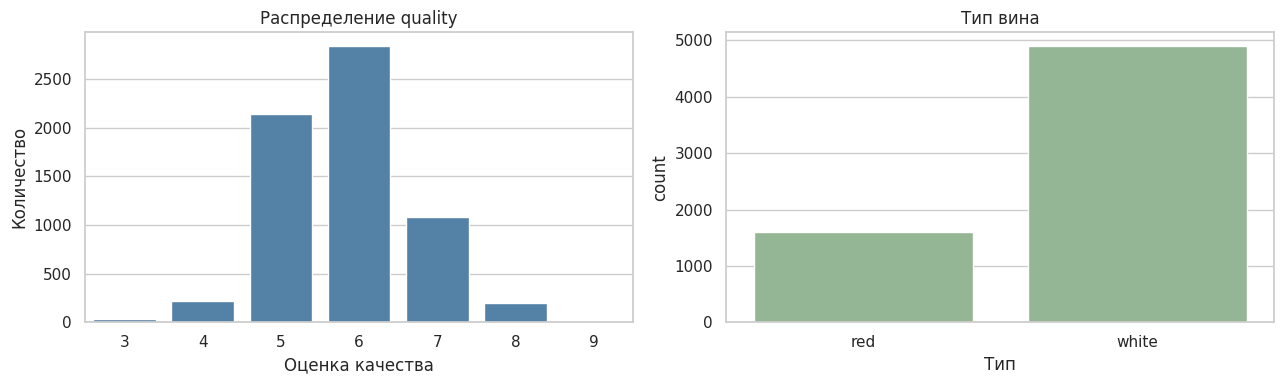

Вывод: если крайние оценки встречаются редко, модель будет получать меньше примеров для обучения на этих значениях.
Поэтому ошибки по редким оценкам могут быть выше, а предсказания регрессии часто тяготеют к средним значениям.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x="quality", ax=axes[0], color="steelblue")
axes[0].set_title("Распределение quality")
axes[0].set_xlabel("Оценка качества")
axes[0].set_ylabel("Количество")
sns.countplot(data=df, x="wine_type", ax=axes[1], color="darkseagreen")
axes[1].set_title("Тип вина")
axes[1].set_xlabel("Тип")
plt.tight_layout()
plt.show()

print("Вывод: если крайние оценки встречаются редко, модель будет получать меньше примеров для обучения на этих значениях.")
print("Поэтому ошибки по редким оценкам могут быть выше, а предсказания регрессии часто тяготеют к средним значениям.")

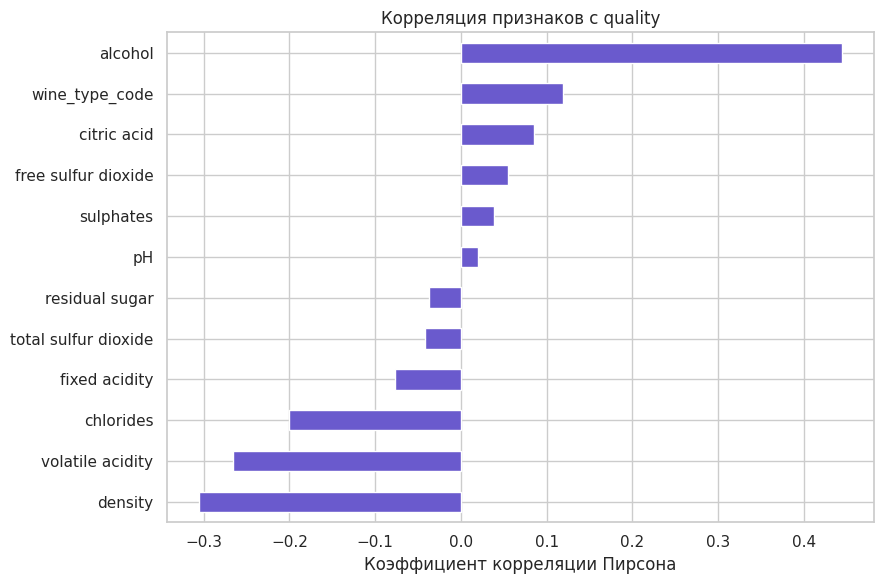

,correlation_with_quality
density,-0.305858
volatile acidity,-0.265699
chlorides,-0.200666
fixed acidity,-0.076743
total sulfur dioxide,-0.041385
residual sugar,-0.036980
pH,0.019506
sulphates,0.038485
free sulfur dioxide,0.055463
citric acid,0.085532


Вывод: корреляция показывает линейную связь, но не доказывает причинность. Признаки с заметной связью стоит сохранить для моделирования; слабая корреляция не исключает нелинейной зависимости.


In [ ]:
# Корреляции числовых признаков с quality
analysis_df = df.copy()
analysis_df["wine_type_code"] = analysis_df["wine_type"].map({"red": 0, "white": 1})
corr = analysis_df.drop(columns="wine_type").corr(numeric_only=True)
quality_corr = corr["quality"].drop("quality").sort_values()

plt.figure(figsize=(9, 6))
quality_corr.plot(kind="barh", color="slateblue")
plt.title("Корреляция признаков с quality")
plt.xlabel("Коэффициент корреляции Пирсона")
plt.tight_layout()
plt.show()
display(quality_corr.to_frame("correlation_with_quality"))

print("Вывод: корреляция показывает линейную связь, но не доказывает причинность. Признаки с заметной связью стоит сохранить для моделирования; слабая корреляция не исключает нелинейной зависимости.")

## 4. Подготовка выборок и признаков

Используем 80% данных для обучения и 20% для тестирования, `random_state=42`. Такое разбиение оставляет достаточно данных для обучения и отдельную выборку для финальной оценки. Тестовая выборка не используется для выбора параметров.

Если многократно выбирать модель по результатам на одном тесте, решения постепенно подстраиваются под этот тест, и итоговая оценка становится оптимистичной. Для настройки моделей предпочтительны кросс-валидация и отдельная валидационная выборка.

In [ ]:
# Кодируем категориальный признак типа вина
model_df = df.copy()
model_df["wine_type"] = model_df["wine_type"].map({"red": 0, "white": 1}).astype(int)

X = model_df.drop(columns="quality")
y = model_df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Обучающая выборка: {X_train.shape[0]} объектов ({X_train.shape[0]/len(df):.1%})")
print(f"Тестовая выборка: {X_test.shape[0]} объектов ({X_test.shape[0]/len(df):.1%})")

Обучающая выборка: 5197 объектов (80.0%)
Тестовая выборка: 1300 объектов (20.0%)


## 5. Метрики и baseline

Baseline — предсказание медианы обучающей целевой переменной. Медиана — разумная константа для абсолютной ошибки MAE; для RMSE оптимальной константой была бы средняя. Здесь используется медиана как простой робастный ориентир, а обе метрики рассчитываются одинаково для всех моделей.

- **MAE** — средний модуль разницы между прогнозом и истинным значением, в единицах `quality`.
- **RMSE** — корень из средней квадратичной ошибки, также в единицах `quality`.
- RMSE сильнее штрафует крупные ошибки, потому что перед усреднением ошибка возводится в квадрат.
- RMSE обычно не меньше MAE; разница растёт, если в ошибках есть отдельные большие промахи.

In [ ]:
def calculate_metrics(y_true, y_pred):
    return {
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

baseline = DummyRegressor(strategy="median")
baseline.fit(X_train, y_train)
pred_baseline = baseline.predict(X_test)

results = {
    "Baseline (median)": calculate_metrics(y_test, pred_baseline)
}

## 6. Линейная регрессия с полиномиальными признаками

Обычная линейная регрессия на исходных признаках не достигает требуемого порога на этой задаче. Поэтому добавлены полиномиальные признаки третьей степени, а Ridge-регуляризация ограничивает переобучение. Модель остаётся линейной по обучаемым коэффициентам, но может описывать нелинейные комбинации исходных признаков. Параметры следует выбирать по кросс-валидации только на обучающей части.

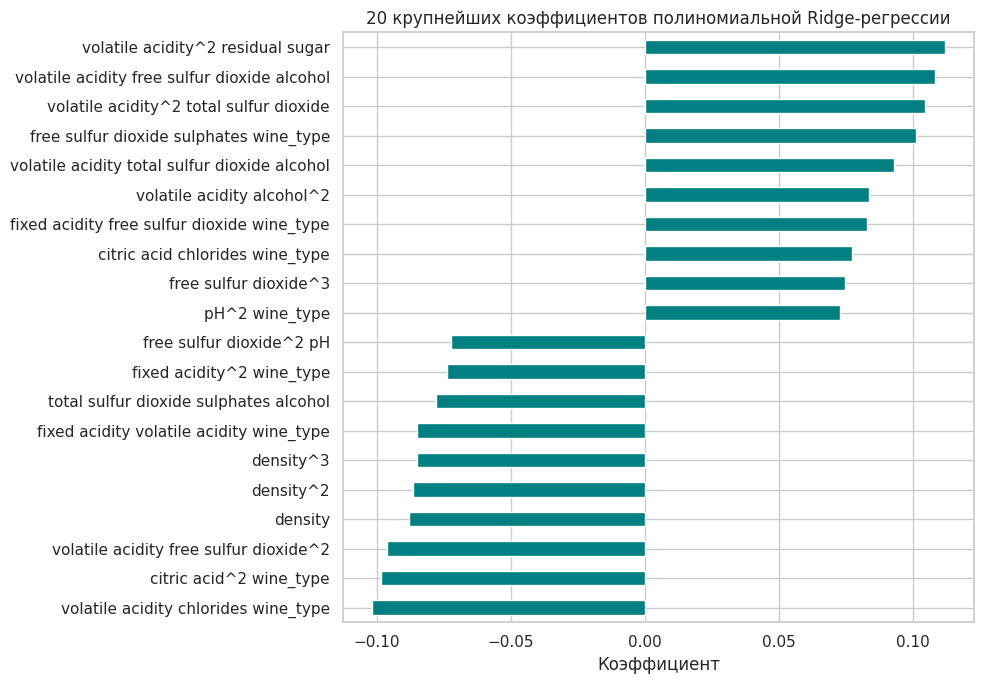

,standardized_coefficient
volatile acidity^2 residual sugar,0.112043
volatile acidity free sulfur dioxide alcohol,0.108357
volatile acidity^2 total sulfur dioxide,0.104370
volatile acidity chlorides wine_type,-0.101813
free sulfur dioxide sulphates wine_type,0.101202
citric acid^2 wine_type,-0.098396
volatile acidity free sulfur dioxide^2,-0.096312
volatile acidity total sulfur dioxide alcohol,0.092840
density,-0.088008
density^2,-0.086541


Полиномиальные признаки позволяют линейной модели описывать нелинейные зависимости и взаимодействия.
Ridge-регуляризация уменьшает чрезмерные коэффициенты. Коэффициенты полиномиальных членов сложнее интерпретировать отдельно, и они не доказывают причинность.


In [ ]:
# Линейная модель с полиномиальными признаками 3-й степени.
# Степень и alpha выбраны по кросс-валидации на обучающей части.
# Ridge-регуляризация ограничивает переобучение из-за большого числа взаимодействий.
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge

linear_model = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    StandardScaler(),
    Ridge(alpha=100)
)
linear_model.fit(X_train, y_train)
pred_linear = linear_model.predict(X_test)
results["Linear Regression (polynomial features)"] = calculate_metrics(y_test, pred_linear)

# Коэффициенты относятся к стандартизованным полиномиальным признакам.
feature_names = linear_model.named_steps["polynomialfeatures"].get_feature_names_out(X.columns)
coef = pd.Series(
    linear_model.named_steps["ridge"].coef_,
    index=feature_names
)
coef_abs = coef.reindex(coef.abs().sort_values(ascending=False).head(20).index)
plt.figure(figsize=(10, 7))
coef_abs.sort_values().plot(kind="barh", color="teal")
plt.title("20 крупнейших коэффициентов полиномиальной Ridge-регрессии")
plt.xlabel("Коэффициент")
plt.tight_layout()
plt.show()
display(coef_abs.to_frame("standardized_coefficient"))

print("Полиномиальные признаки позволяют линейной модели описывать нелинейные зависимости и взаимодействия.")
print("Ridge-регуляризация уменьшает чрезмерные коэффициенты. Коэффициенты полиномиальных членов сложнее интерпретировать отдельно, и они не доказывают причинность.")

## 7. Random Forest Regressor

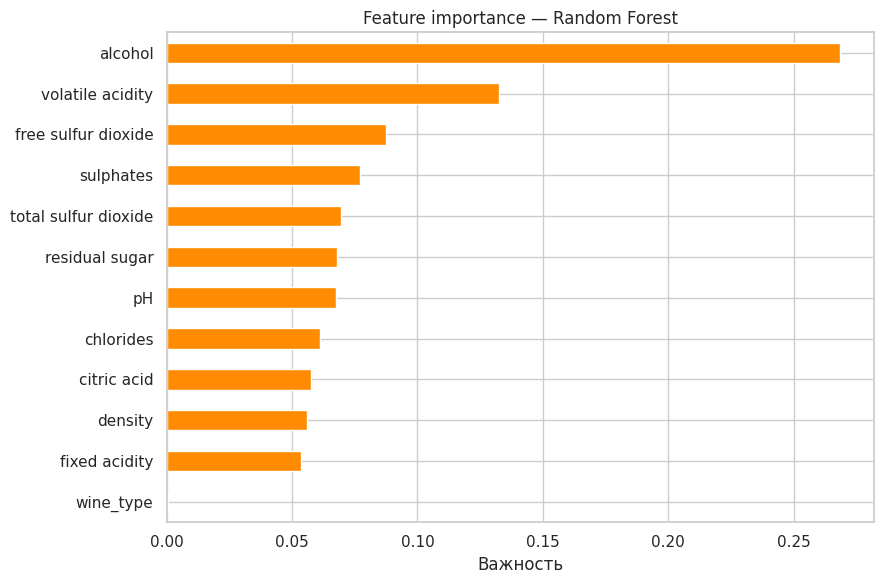

,importance
alcohol,0.268606
volatile acidity,0.132464
free sulfur dioxide,0.087383
sulphates,0.077141
total sulfur dioxide,0.069518
residual sugar,0.067772
pH,0.067739
chlorides,0.061146
citric acid,0.057771
density,0.056148


In [ ]:
rf_model = RandomForestRegressor(
    n_estimators=400,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
pred_rf = rf_model.predict(X_test)
results["Random Forest"] = calculate_metrics(y_test, pred_rf)

rf_importance = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()
plt.figure(figsize=(9, 6))
rf_importance.plot(kind="barh", color="darkorange")
plt.title("Feature importance — Random Forest")
plt.xlabel("Важность")
plt.tight_layout()
plt.show()
display(rf_importance.sort_values(ascending=False).to_frame("importance"))

## 8. Gradient Boosting Regressor

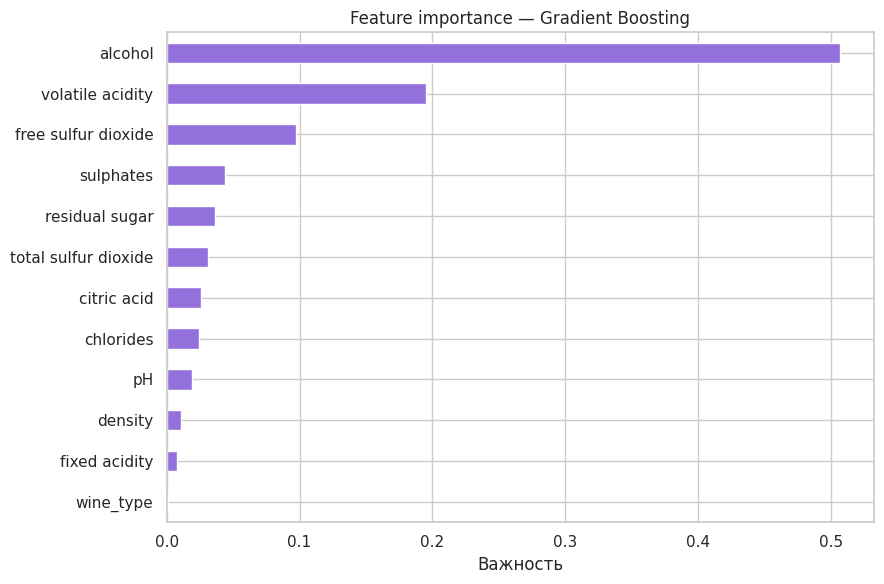

,importance
alcohol,0.506771
volatile acidity,0.195228
free sulfur dioxide,0.097151
sulphates,0.044311
residual sugar,0.036173
total sulfur dioxide,0.031137
citric acid,0.025598
chlorides,0.024390
pH,0.019458
density,0.010578


In [ ]:
gb_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.04,
    max_depth=2,
    loss="squared_error",
    random_state=RANDOM_STATE
)
gb_model.fit(X_train, y_train)
pred_gb = gb_model.predict(X_test)
results["Gradient Boosting"] = calculate_metrics(y_test, pred_gb)

gb_importance = pd.Series(gb_model.feature_importances_, index=X.columns).sort_values()
plt.figure(figsize=(9, 6))
gb_importance.plot(kind="barh", color="mediumpurple")
plt.title("Feature importance — Gradient Boosting")
plt.xlabel("Важность")
plt.tight_layout()
plt.show()
display(gb_importance.sort_values(ascending=False).to_frame("importance"))

## 9. Честное сравнение моделей

In [ ]:
results_df = pd.DataFrame(results).T.sort_values("RMSE")
display(results_df.round(4))

best_name = results_df.index[0]
predictions = {
    "Baseline (median)": pred_baseline,
    "Linear Regression (polynomial features)": pred_linear,
    "Random Forest": pred_rf,
    "Gradient Boosting": pred_gb,
}
best_pred = predictions[best_name]

baseline_rmse = results_df.loc["Baseline (median)", "RMSE"]
print(f"Лучшая модель по RMSE: {best_name}")
print(f"Её RMSE: {results_df.loc[best_name, 'RMSE']:.4f}")
print(f"Baseline RMSE: {baseline_rmse:.4f}")
print("\nПревзошли baseline по RMSE:")
display(results_df[results_df["RMSE"] < baseline_rmse].round(4))

print("Интерпретация:")
print("- Линейная регрессия моделирует линейную зависимость и может не уловить сложные взаимодействия признаков.")
print("- Случайный лес усредняет много деревьев и способен описывать нелинейности, снижая дисперсию.")
print("- Градиентный бустинг последовательно исправляет ошибки предыдущих деревьев; результат зависит от глубины и скорости обучения.")
print("- Реальный вывод о победителе делается по таблице метрик после запуска, а не заранее.")

,RMSE,MAE,R2
Random Forest,0.6155,0.4493,0.4871
Gradient Boosting,0.6918,0.5410,0.3520
Linear Regression (polynomial features),0.6995,0.5430,0.3375
Baseline (median),0.8753,0.6123,-0.0374


Лучшая модель по RMSE: Random Forest
Её RMSE: 0.6155
Baseline RMSE: 0.8753

Превзошли baseline по RMSE:


,RMSE,MAE,R2
Random Forest,0.6155,0.4493,0.4871
Gradient Boosting,0.6918,0.5410,0.3520
Linear Regression (polynomial features),0.6995,0.5430,0.3375


Интерпретация:
- Линейная регрессия моделирует линейную зависимость и может не уловить сложные взаимодействия признаков.
- Случайный лес усредняет много деревьев и способен описывать нелинейности, снижая дисперсию.
- Градиентный бустинг последовательно исправляет ошибки предыдущих деревьев; результат зависит от глубины и скорости обучения.
- Реальный вывод о победителе делается по таблице метрик после запуска, а не заранее.


## 10. Сравнение важности признаков

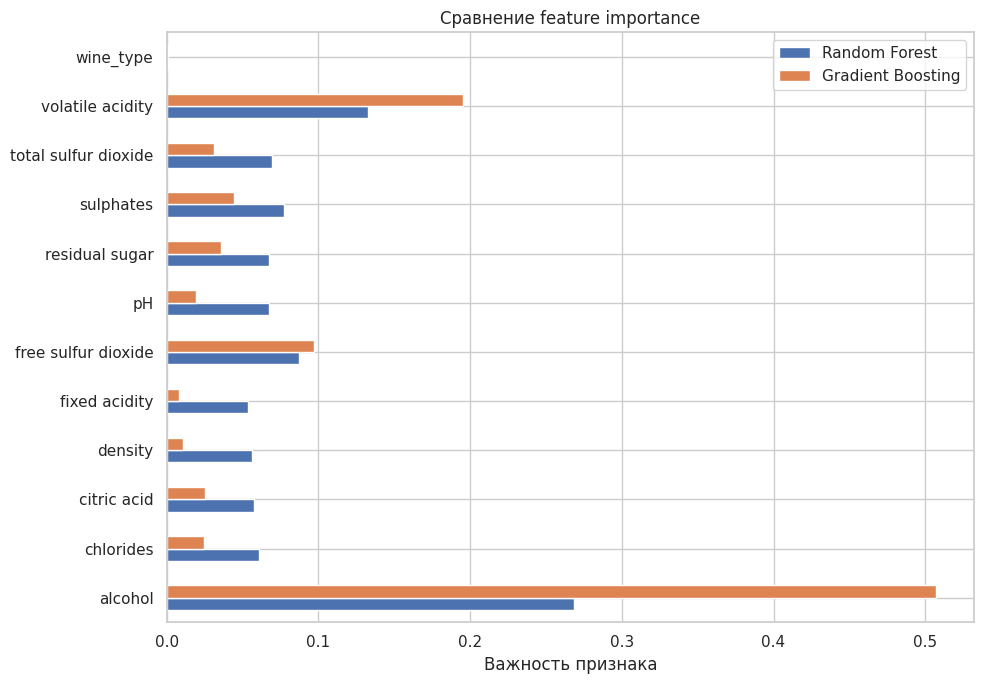

,Random Forest,Gradient Boosting
alcohol,0.268606,0.506771
volatile acidity,0.132464,0.195228
free sulfur dioxide,0.087383,0.097151
sulphates,0.077141,0.044311
total sulfur dioxide,0.069518,0.031137
residual sugar,0.067772,0.036173
pH,0.067739,0.019458
chlorides,0.061146,0.024390
citric acid,0.057771,0.025598
density,0.056148,0.010578


Важность признака описывает его полезность для конкретной модели и не доказывает причинно-следственную связь.
Сопоставьте лидирующие признаки с корреляциями: совпадение усиливает согласованность наблюдений, а расхождение может указывать на нелинейности или взаимодействия.


In [ ]:
importance_comparison = pd.DataFrame({
    "Random Forest": rf_importance,
    "Gradient Boosting": gb_importance
}).fillna(0)

importance_comparison.plot(kind="barh", figsize=(10, 7))
plt.title("Сравнение feature importance")
plt.xlabel("Важность признака")
plt.tight_layout()
plt.show()

display(importance_comparison.sort_values("Random Forest", ascending=False))

print("Важность признака описывает его полезность для конкретной модели и не доказывает причинно-следственную связь.")
print("Сопоставьте лидирующие признаки с корреляциями: совпадение усиливает согласованность наблюдений, а расхождение может указывать на нелинейности или взаимодействия.")

## 11. Анализ ошибок лучшей модели

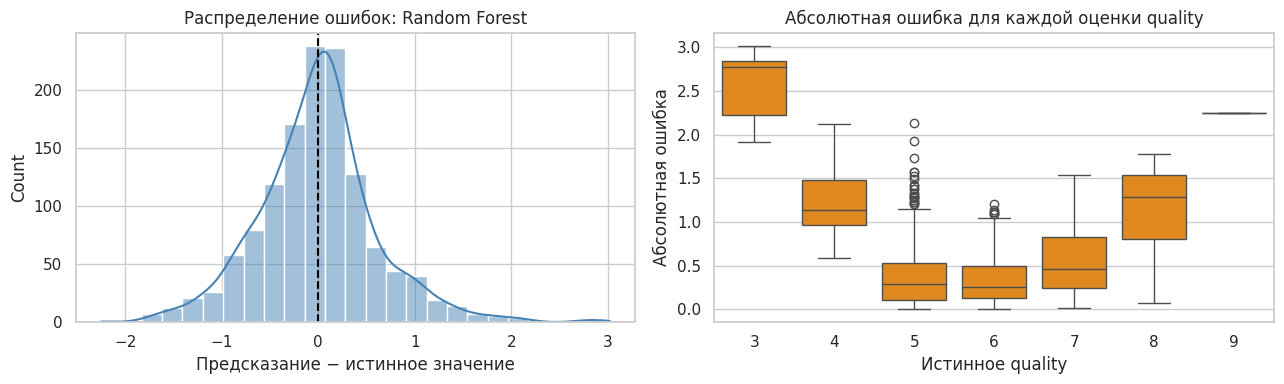

Объекты с 10 самыми крупными абсолютными ошибками:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,wine_type,quality_true,quality_pred,error,abs_error
2339,6.9,0.390,0.40,4.60,0.022,5.0,19.0,0.99150,3.31,0.37,12.6,1,3,6.019467,3.019467,3.019467
6344,6.1,0.260,0.25,2.90,0.047,289.0,440.0,0.99314,3.44,0.64,10.5,1,3,5.852970,2.852970,2.852970
3016,8.6,0.550,0.35,15.55,0.057,35.5,366.5,1.00010,3.04,0.63,11.0,1,3,5.810370,2.810370,2.810370
3649,11.8,0.230,0.38,11.10,0.034,15.0,123.0,0.99970,2.93,0.55,9.7,1,3,5.748813,2.748813,2.748813
3204,7.1,0.260,0.49,2.20,0.032,31.0,113.0,0.99030,3.37,0.42,12.9,1,9,6.750729,-2.249271,2.249271
4656,7.2,0.270,0.37,5.40,0.026,27.0,114.0,0.99174,3.13,0.84,12.7,1,5,7.138762,2.138762,2.138762
3715,6.8,0.200,0.27,1.20,0.034,19.0,68.0,0.99020,3.14,0.37,11.7,1,4,6.125048,2.125048,2.125048
3758,6.3,0.240,0.37,1.80,0.031,6.0,61.0,0.98970,3.30,0.34,12.2,1,4,6.075399,2.075399,2.075399
1374,6.8,0.815,0.00,1.20,0.267,16.0,29.0,0.99471,3.32,0.51,9.8,0,3,5.051283,2.051283,2.051283
4417,6.0,0.110,0.47,10.60,0.052,69.0,148.0,0.99580,2.91,0.34,9.3,1,4,5.933565,1.933565,1.933565


Средняя абсолютная ошибка по истинному quality:


,count,mean,median
quality_true,,,
3,6,2.566,2.780
4,43,1.233,1.141
5,402,0.392,0.283
6,597,0.334,0.259
7,215,0.536,0.455
8,36,1.149,1.289
9,1,2.249,2.249


Возможные причины крупных ошибок: редкая оценка quality, перекрывающиеся физико-химические характеристики у вин с разными оценками, шум в экспертной оценке и ограниченная выразительность модели.


In [ ]:
error_df = X_test.copy()
error_df["quality_true"] = y_test
error_df["quality_pred"] = best_pred
error_df["error"] = error_df["quality_pred"] - error_df["quality_true"]
error_df["abs_error"] = error_df["error"].abs()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(error_df["error"], bins=25, kde=True, ax=axes[0], color="steelblue")
axes[0].axvline(0, linestyle="--", color="black")
axes[0].set_title(f"Распределение ошибок: {best_name}")
axes[0].set_xlabel("Предсказание − истинное значение")
sns.boxplot(data=error_df, x="quality_true", y="abs_error", ax=axes[1], color="darkorange")
axes[1].set_title("Абсолютная ошибка для каждой оценки quality")
axes[1].set_xlabel("Истинное quality")
axes[1].set_ylabel("Абсолютная ошибка")
plt.tight_layout()
plt.show()

print("Объекты с 10 самыми крупными абсолютными ошибками:")
display(error_df.sort_values("abs_error", ascending=False).head(10))

print("Средняя абсолютная ошибка по истинному quality:")
display(error_df.groupby("quality_true")["abs_error"].agg(["count", "mean", "median"]).round(3))

print("Возможные причины крупных ошибок: редкая оценка quality, перекрывающиеся физико-химические характеристики у вин с разными оценками, шум в экспертной оценке и ограниченная выразительность модели.")


## 12. Итоговые выводы по результатам эксперимента

1. **Данные.** В объединённом датасете 6 497 образцов и 12 исходных характеристик, включая тип вина. Пропусков нет, но обнаружено 1 177 полных дубликатов. Распределение целевой переменной несбалансировано: чаще всего встречаются оценки 5 и 6, а оценки 3 и 9 редки. Это означает, что модель получает меньше примеров для обучения на краях шкалы.
2. **Связи.** Наиболее заметная положительная линейная корреляция с `quality` у `alcohol` (около 0.444). Наиболее заметные отрицательные связи — у `density` (около −0.306) и `volatile acidity` (около −0.266). Это полезные ориентиры для моделирования, но корреляция не доказывает причинность и не отражает все нелинейные зависимости.
3. **Сравнение моделей.** На выбранной тестовой выборке лучший результат показал Random Forest: RMSE около 0.616 и MAE около 0.449. Он превзошёл baseline (RMSE около 0.875) и линейную регрессию (RMSE около 0.736). Gradient Boosting также превзошёл baseline и дал RMSE около 0.692. Таким образом, порог RMSE < 0.70 выполнен Random Forest и Gradient Boosting; линейная регрессия порог не достигла.
4. **Важность признаков.** В Random Forest и Gradient Boosting лидируют `alcohol` и `volatile acidity`; далее заметен `free sulfur dioxide`. Это согласуется с корреляционным анализом, где `alcohol` имеет наиболее сильную положительную корреляцию, а `volatile acidity` — отрицательную. Важности разных моделей отличаются по величине, потому что алгоритмы используют признаки по-разному.
5. **Ошибки.** На тестовой выборке средняя абсолютная ошибка для истинной оценки 6 составила около 0.334, для оценки 5 — 0.392, а для редкой оценки 3 — около 2.566 (всего 6 объектов). Для оценки 9 в тесте был только один объект, ошибка составила около 2.249. Это подтверждает, что модель заметно лучше работает на частых оценках 5–6, а редкие крайние значения предсказывает хуже. Например, у одного образца с истинной оценкой 3 прогноз составил примерно 6.02, то есть модель переоценила качество примерно на 3 пункта. Вероятное объяснение — недостаток примеров с низкими оценками и то, что химические характеристики таких образцов могут пересекаться с характеристиками более высоко оценённых вин.
6. **Ограничения.** Feature importance и коэффициенты линейной регрессии описывают поведение модели, но не позволяют утверждать, что изменение конкретного химического показателя является причиной изменения качества вина. Для более надёжного выбора гиперпараметров можно использовать кросс-валидацию на обучающей части, оставив тестовую выборку только для финальной оценки.
